<a href="https://colab.research.google.com/github/riasad30/Thesis/blob/main/last_update_file_new.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =====================================================================
# CODE 1: Apply SMOTE to the FULL dataset and save it as a new dataset
# Google Colab
# =====================================================================
# Before running: upload "default_of_credit_card_clients.xls" in the
# Colab Files panel (left sidebar → folder icon → upload).

!pip install -q imbalanced-learn xlrd

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

FILE_PATH = "/content/default of credit card clients.xls"   # change if your file is elsewhere
OUTPUT_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load data ----------
df = pd.read_excel(FILE_PATH, header=1)        # row 0 of the file is an extra header (X1, X2, ...)
df = df.drop(columns=["ID"])
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Original shape:", X.shape)
print("Original class counts:\n", y.value_counts().sort_index(), "\n")

# ---------- 2. SMOTE on the full dataset ----------
# Scale first so SMOTE's nearest-neighbour distances are fair across columns
# (LIMIT_BAL is in the hundreds of thousands, SEX is 1/2).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

smote = SMOTE(k_neighbors=5, random_state=RANDOM_STATE)
X_res_scaled, y_res = smote.fit_resample(X_scaled, y)

# Convert back to the original units so the new dataset is readable
X_res = pd.DataFrame(scaler.inverse_transform(X_res_scaled), columns=X.columns)

df_smote = X_res.copy()
df_smote[TARGET] = y_res.values

print("After SMOTE shape:", df_smote.shape)
print("After SMOTE class counts:\n", df_smote[TARGET].value_counts().sort_index())
print("Synthetic rows added:", len(df_smote) - len(df))

# ---------- 3. Save the new dataset ----------
df_smote.to_csv(OUTPUT_PATH, index=False)
print("\nSaved:", OUTPUT_PATH)
display(df_smote.head())

# Optional: download the file to your computer
# from google.colab import files
# files.download(OUTPUT_PATH)

Original shape: (30000, 23)
Original class counts:
 default payment next month
0    23364
1     6636
Name: count, dtype: int64 

After SMOTE shape: (46728, 24)
After SMOTE class counts:
 default payment next month
0    23364
1    23364
Name: count, dtype: int64
Synthetic rows added: 16728

Saved: /content/credit_card_smote.csv


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000.0,2.0,2.0,1.0,24.0,2.0,2.0,-1.0,-1.0,-2.0,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2.0,2.0,2.0,26.0,-1.0,2.0,0.0,0.0,0.0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2.0,2.0,2.0,34.0,0.0,0.0,0.0,0.0,0.0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2.0,2.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1.0,2.0,1.0,57.0,-1.0,0.0,-1.0,0.0,0.0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8893  (12.6s)
RandomForest: accuracy = 0.8523  (34.6s)
Bagging: accuracy = 0.8340  (12.3s)
KNeighbors: accuracy = 0.7786  (2.0s)
DecisionTree: accuracy = 0.7600  (1.6s)
AdaBoost: accuracy = 0.7275  (6.9s)
SVC: accuracy = 0.7130  (109.0s)
LogisticRegression: accuracy = 0.6665  (0.4s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8901    0.8877    0.8889      4664
   Class 1 (Default)     0.8884    0.8909    0.8896      4682

            accuracy                         0.8893      9346
           macro avg     0.8893    0.8893    0.8893      9346
        weighted avg     0.8893    0.8893    0.8893      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8323    0.8819    0.8563      4664
   Class 1 (Default)     0.8749   

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            88.93     89.01  88.77  88.89    88.77     88.84  89.09   
RandomForest          85.23     83.23  88.19  85.63    88.19     87.49  82.29   
Bagging               83.40     80.08  88.85  84.24    88.85     87.53  77.98   
KNeighbors            77.86     85.36  67.15  75.17    67.15     73.01  88.53   
DecisionTree          76.00     76.68  74.59  75.62    74.59     75.36  77.40   
AdaBoost              72.75     69.07  82.20  75.07    82.20     78.13  63.33   
SVC                   71.30     67.05  83.58  74.40    83.58     78.31  59.08   
LogisticRegression    66.65     65.91  68.70  67.28    68.70     67.45  64.61   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.96    89.09  
RandomForest        84.81    82.29  
Bagging             82.48    77.98  
KNeighbors          80.03    88.53  
DecisionTree        76.37    77.40  
AdaBoost            69.95    63.33  
SVC                 67.35    59.08  
LogisticRegression  66.00    64.61

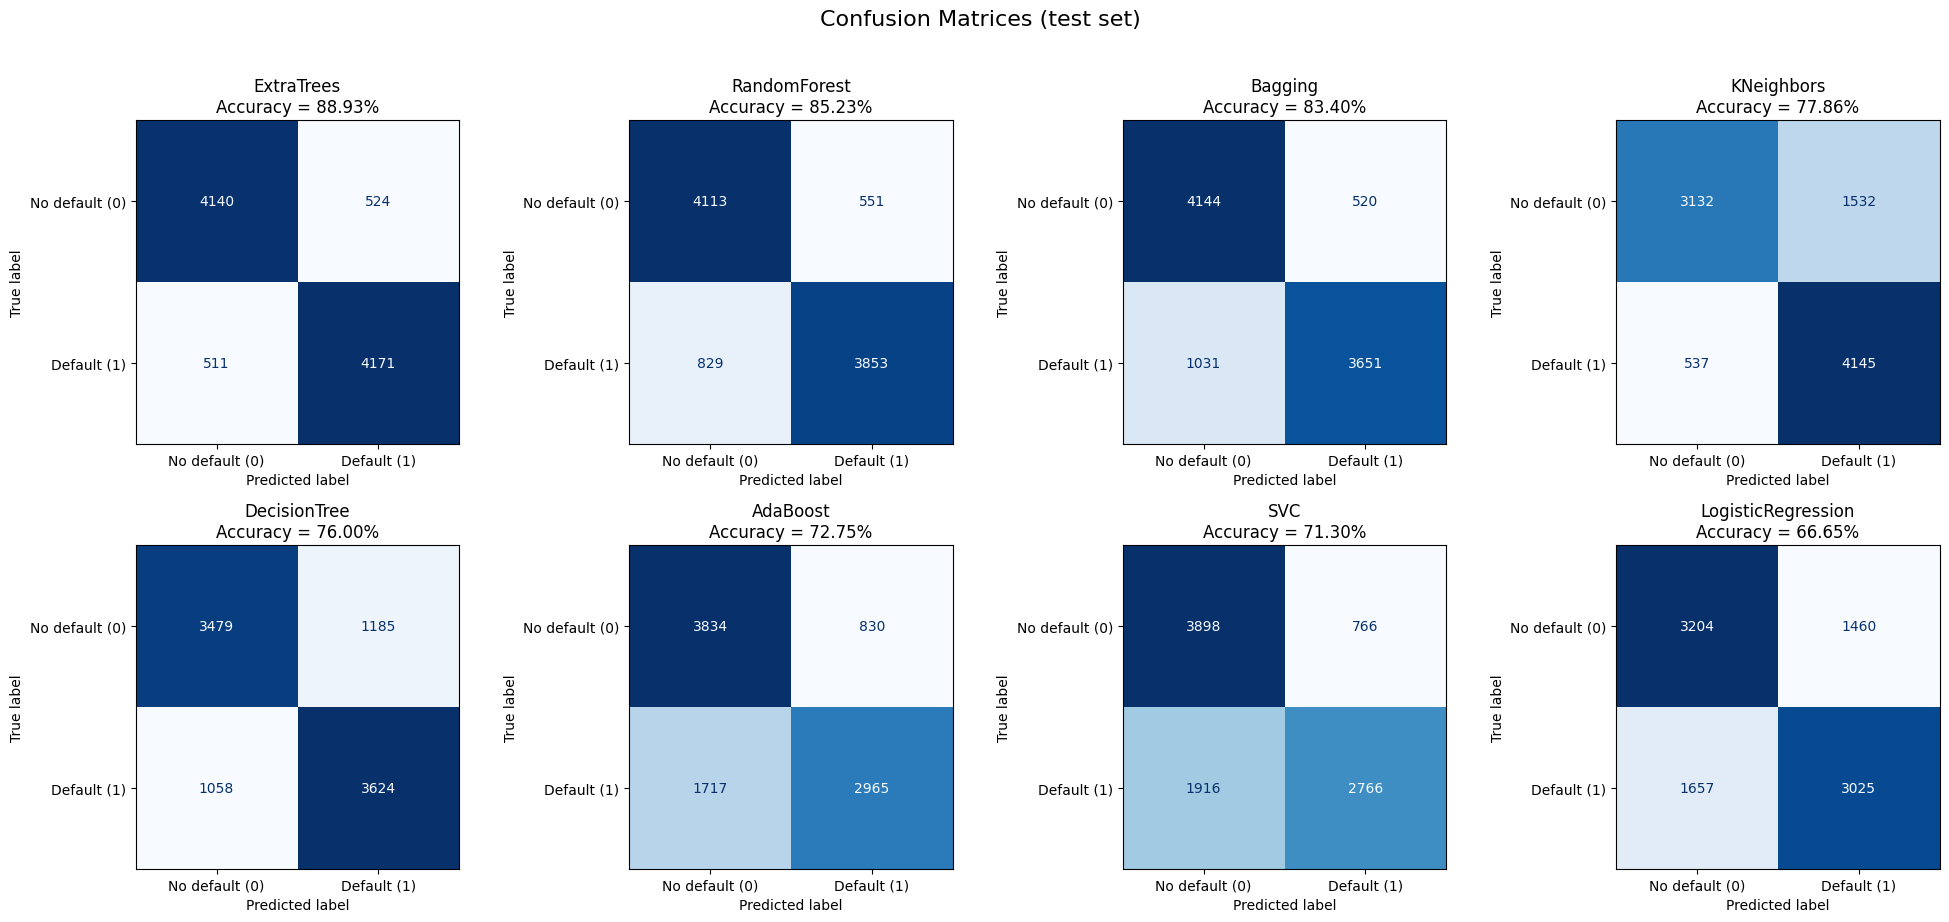

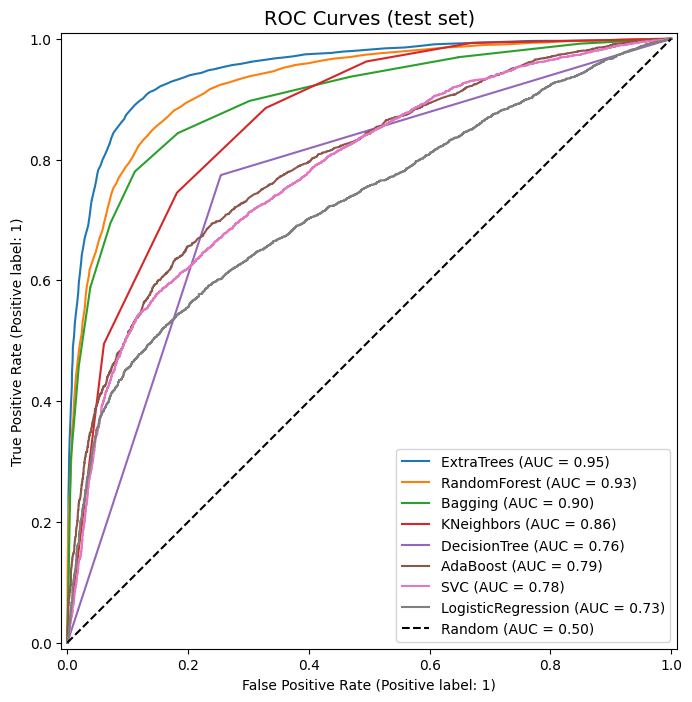


Best model on the test set: ExtraTrees (0.8893)

5-Fold Cross-Validation Accuracy — ExtraTrees
  Fold 1: 0.8933
  Fold 2: 0.8900
  Fold 3: 0.8910
  Fold 4: 0.8856
  Fold 5: 0.8920
  Mean : 0.8904
  Std  : 0.0026


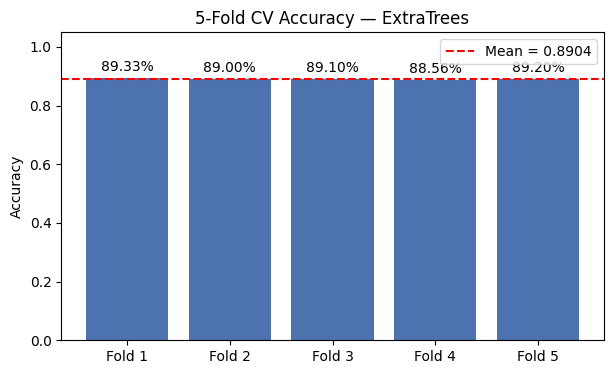

In [ ]:
# =====================================================================
# CODE 2: Train 8 models on the SMOTE dataset (from Code 1)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load SMOTE dataset & split 80/20 ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])









# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)



      # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

Feature engineering ON: 36 features (23 original + 13 new)
Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8798  (17.5s)
RandomForest: accuracy = 0.8470  (44.0s)
Bagging: accuracy = 0.8274  (14.9s)
KNeighbors: accuracy = 0.7825  (4.3s)
DecisionTree: accuracy = 0.7712  (2.5s)
AdaBoost: accuracy = 0.7261  (10.9s)
SVC: accuracy = 0.7398  (136.8s)
LogisticRegression: accuracy = 0.7127  (0.4s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8797    0.8795    0.8796      4664
   Class 1 (Default)     0.8800    0.8802    0.8801      4682

            accuracy                         0.8798      9346
           macro avg     0.8798    0.8798    0.8798      9346
        weighted avg     0.8798    0.8798    0.8798      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8295    0

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            87.98     87.97  87.95  87.96    87.95     88.00  88.02   
RandomForest          84.70     82.95  87.29  85.06    87.29     86.64  82.12   
Bagging               82.74     79.91  87.39  83.48    87.39     86.15  78.11   
KNeighbors            78.25     84.50  69.08  76.02    69.08     73.94  87.38   
DecisionTree          77.12     78.04  75.36  76.68    75.36     76.27  78.88   
SVC                   73.98     70.73  81.65  75.80    81.65     78.39  66.34   
AdaBoost              72.61     69.66  79.93  74.44    79.93     76.56  65.31   
LogisticRegression    71.27     67.84  80.68  73.70    80.68     76.28  61.90   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.01    88.02  
RandomForest        84.32    82.12  
Bagging             81.93    78.11  
KNeighbors          80.10    87.38  
DecisionTree        77.55    78.88  
SVC                 71.86    66.34  
AdaBoost            70.49    65.31  
LogisticRegression  68.34    61.90

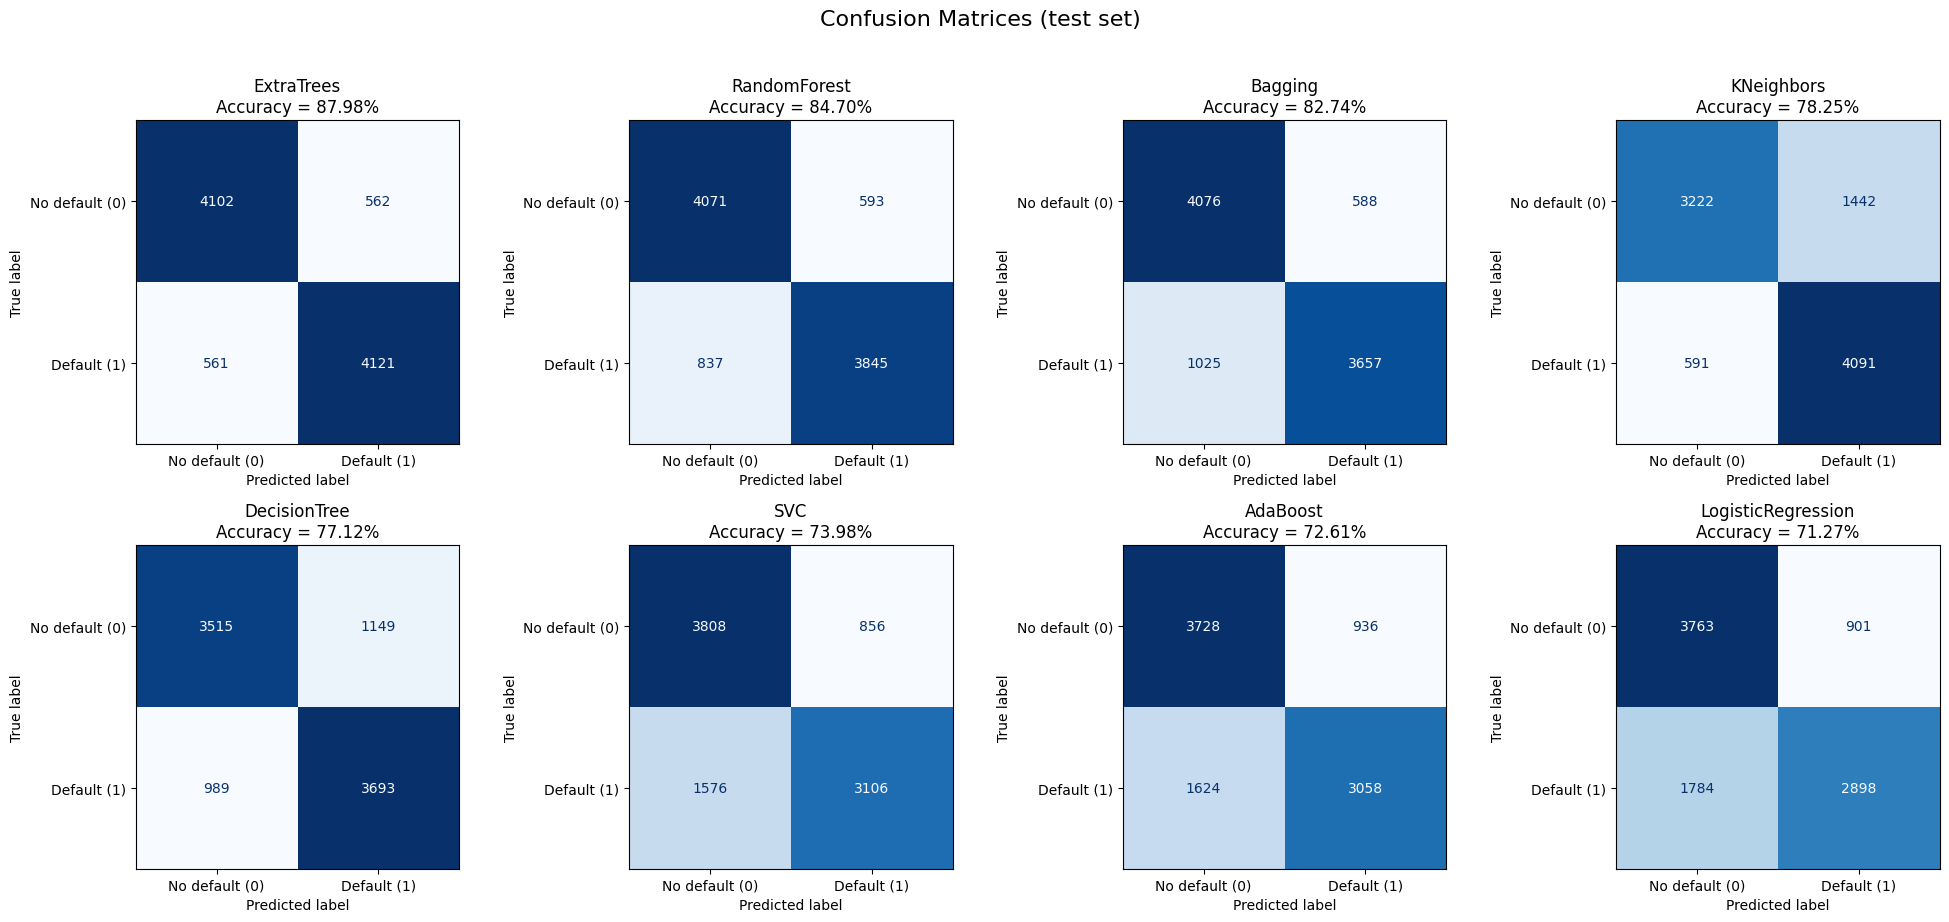

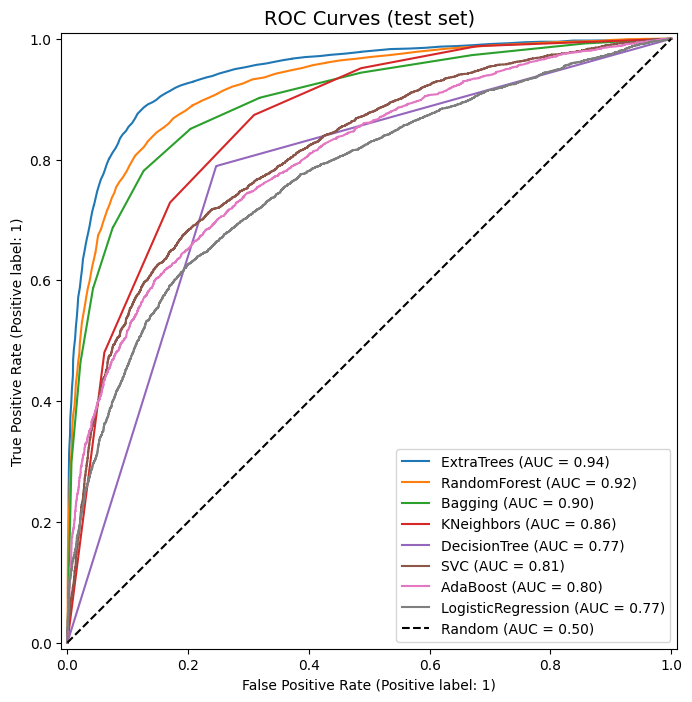


Best model on the test set: ExtraTrees (0.8798)

5-Fold Cross-Validation Accuracy — ExtraTrees
  Fold 1: 0.8812
  Fold 2: 0.8818
  Fold 3: 0.8804
  Fold 4: 0.8764
  Fold 5: 0.8800
  Mean : 0.8800
  Std  : 0.0019


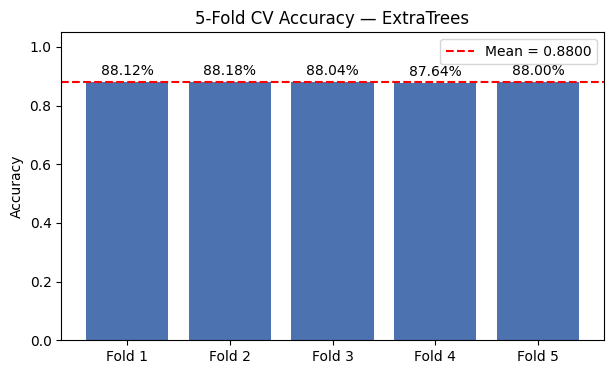

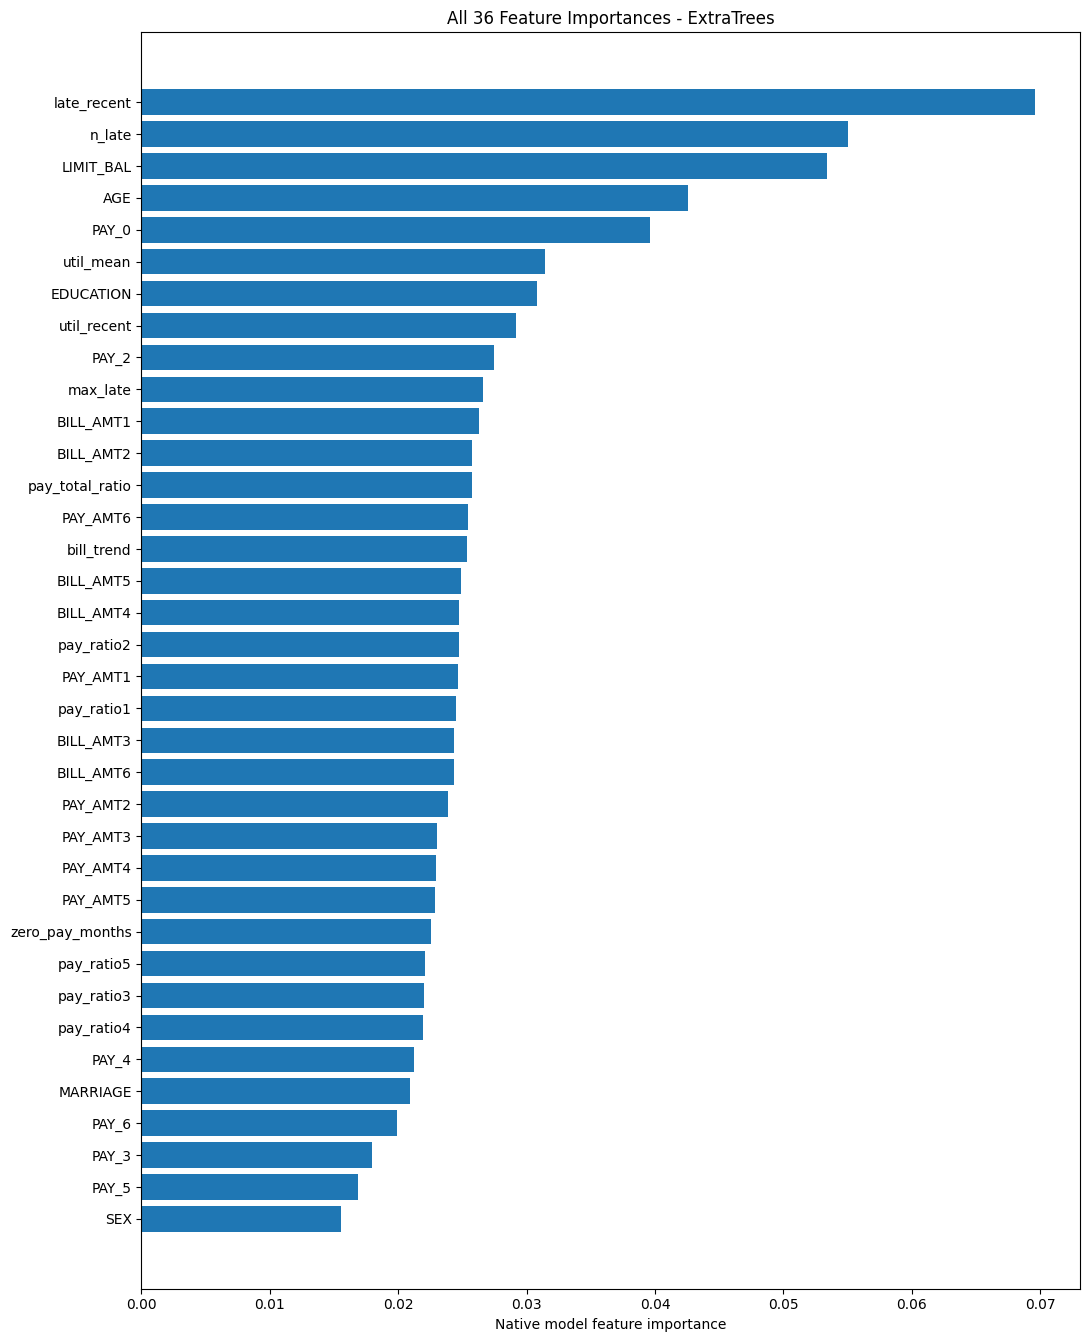

In [ ]:
# =====================================================================
# CODE 3: Train 8 models on the SMOTE dataset (from Code 1)
#   - Feature engineering (13 new features from the original 23)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42
USE_FEATURE_ENGINEERING = True     # set to False to run with only the original 23 features

# ---------- 1. Load SMOTE dataset ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

# ---------- 1b. Feature engineering ----------
# Every new feature is computed row by row from that client's own values only,
# so it can be done before the split without using information from other rows.
PAY_COLS  = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]           # repayment status, newest -> oldest
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]                          # bill amount,       newest -> oldest
PAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]                           # amount paid,       newest -> oldest

def add_features(X):
    X = X.copy()
    pay, bill, pamt = X[PAY_COLS], X[BILL_COLS], X[PAMT_COLS]
    limit = X["LIMIT_BAL"]

    # Repayment behaviour
    X["n_late"]          = (pay > 0).sum(axis=1)                 # months with a payment delay (out of 6)
    X["max_late"]        = pay.max(axis=1)                       # worst delay in months
    X["late_recent"]     = (X[["PAY_0", "PAY_2"]] > 0).sum(axis=1)   # delays in the last 2 months
    X["zero_pay_months"] = (pamt <= 0).sum(axis=1)               # months with no payment at all

    # Credit utilisation
    X["util_recent"] = X["BILL_AMT1"] / limit                    # latest bill / credit limit
    X["util_mean"]   = bill.mean(axis=1) / limit                 # average bill / credit limit

    # How much of the previous bill was paid each month (clipped to avoid huge ratios when the bill is ~0)
    for i in range(1, 6):
        X[f"pay_ratio{i}"] = (X[f"PAY_AMT{i}"] / X[f"BILL_AMT{i+1}"].clip(lower=1)).clip(0, 5)
    X["pay_total_ratio"] = (pamt.sum(axis=1) / bill.sum(axis=1).clip(lower=1)).clip(0, 5)

    # Trend of the bill over 6 months (positive = debt is growing)
    X["bill_trend"] = X["BILL_AMT1"] - X["BILL_AMT6"]
    return X

if USE_FEATURE_ENGINEERING:
    X = add_features(X)
    print(f"Feature engineering ON: {X.shape[1]} features (23 original + {X.shape[1] - 23} new)")
else:
    print(f"Feature engineering OFF: {X.shape[1]} original features")

# ---------- 1c. Split 80/20 ----------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)          # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

# ---------- 8. Native feature importance: ALL features ----------
# This is the estimator's native importance, not SHAP or LIME.
best_pipe, _ = fitted[best_name]
model = best_pipe.named_steps["model"]
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
    plt.figure(figsize=(11, max(7, 0.32 * len(imp) + 2)))
    plt.barh(imp.index, imp.values)
    plt.xlabel("Native model feature importance")
    plt.title(f"All {len(imp)} Feature Importances - {best_name}")
    plt.tight_layout()
    plt.show()


In [ ]:
best_model = fitted[best_name][0]

In [ ]:
# ============================================================
# Stacking Ensemble Model
# ============================================================

from sklearn.ensemble import (
    StackingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)


# Base learners
stack_base_models = [

    (
        'rf',
        RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_SEED,
            class_weight='balanced',
            n_jobs=-1
        )
    ),


    (
        'extra_tree',
        ExtraTreesClassifier(
            n_estimators=300,
            random_state=RANDOM_SEED,
            class_weight='balanced',
            n_jobs=-1
        )
    ),


    (
        'gb',
        GradientBoostingClassifier(
            random_state=RANDOM_SEED
        )
    )
]


# Meta learner
stack_model = StackingClassifier(

    estimators=stack_base_models,

    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_SEED
    ),

    cv=5,

    n_jobs=-1,

    passthrough=False
)



# Train
stack_model.fit(
    X_train_xai,
    y_train
)



# Prediction

stack_pred = stack_model.predict(
    X_test_xai
)


stack_prob = stack_model.predict_proba(
    X_test_xai
)[:,1]



# Performance

stack_results = {

    "Model":
    "Stacking Ensemble",

    "Accuracy":
    accuracy_score(y_test, stack_pred),

    "Precision":
    precision_score(y_test, stack_pred),

    "Recall":
    recall_score(y_test, stack_pred),

    "F1":
    f1_score(y_test, stack_pred),

    "ROC_AUC":
    roc_auc_score(y_test, stack_prob)

}


print("===== Stacking Ensemble =====")

print(
    classification_report(
        y_test,
        stack_pred
    )
)


stack_results

===== Stacking Ensemble =====
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      4664
           1       0.88      0.87      0.88      4682

    accuracy                           0.88      9346
   macro avg       0.88      0.88      0.88      9346
weighted avg       0.88      0.88      0.88      9346



{'Model': 'Stacking Ensemble',
 'Accuracy': 0.878022683500963,
 'Precision': 0.8825053995680345,
 'Recall': 0.8727039726612559,
 'F1': 0.8775773195876289,
 'ROC_AUC': np.float64(0.9446810272251747)}

In [ ]:
# ============================================================
# Soft Voting Ensemble
# ============================================================

from sklearn.ensemble import VotingClassifier


voting_model = VotingClassifier(

    estimators=[

        (
            'rf',
            RandomForestClassifier(
                n_estimators=300,
                random_state=RANDOM_SEED,
                class_weight='balanced',
                n_jobs=-1
            )
        ),


        (
            'extra',
            ExtraTreesClassifier(
                n_estimators=300,
                random_state=RANDOM_SEED,
                class_weight='balanced',
                n_jobs=-1
            )
        ),


        (
            'gb',
            GradientBoostingClassifier(
                random_state=RANDOM_SEED
            )
        )

    ],

    voting='soft',

    n_jobs=-1

)



# Train

voting_model.fit(
    X_train_xai,
    y_train
)



# Prediction

voting_pred = voting_model.predict(
    X_test_xai
)


voting_prob = voting_model.predict_proba(
    X_test_xai
)[:,1]



# Performance

voting_results = {

    "Model":
    "Soft Voting Ensemble",

    "Accuracy":
    accuracy_score(y_test, voting_pred),

    "Precision":
    precision_score(y_test, voting_pred),

    "Recall":
    recall_score(y_test, voting_pred),

    "F1":
    f1_score(y_test, voting_pred),

    "ROC_AUC":
    roc_auc_score(y_test, voting_prob)

}



print("===== Soft Voting Ensemble =====")


print(
    classification_report(
        y_test,
        voting_pred
    )
)


voting_results

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


===== Soft Voting Ensemble =====
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      4664
           1       0.88      0.84      0.86      4682

    accuracy                           0.86      9346
   macro avg       0.86      0.86      0.86      9346
weighted avg       0.86      0.86      0.86      9346



{'Model': 'Soft Voting Ensemble',
 'Accuracy': 0.86047506954847,
 'Precision': 0.8755002223210315,
 'Recall': 0.8410935497650577,
 'F1': 0.8579520697167756,
 'ROC_AUC': np.float64(0.9341486005672613)}

In [ ]:
# ============================================================
# Ensemble Model Comparison
# ============================================================

ensemble_comparison = pd.DataFrame(
    [
        stack_results,
        voting_results
    ]
)


ensemble_comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Stacking Ensemble,0.878023,0.882505,0.872704,0.877577,0.944681
1,Soft Voting Ensemble,0.860475,0.875500,0.841094,0.857952,0.934149


In [ ]:
# ============================================================
# Final Best Model Selection
# ============================================================

model = stack_model
model_name = "Stacking Ensemble"


def predict_default(X):

    return model.predict_proba(X)[:, 1]


print("Selected XAI Model:", model_name)

Selected XAI Model: Stacking Ensemble


In [ ]:
# ============================================================
# SHAP Explanation - Stacking Ensemble
# ============================================================

import shap
import numpy as np
import pandas as pd


# Background samples
X_background = shap.sample(
    X_train_xai,
    100,
    random_state=RANDOM_SEED
)


# SHAP prediction function
def shap_predict(X):

    X = pd.DataFrame(
        X,
        columns=X_train_xai.columns
    )

    return model.predict_proba(X)[:,1]


# Create SHAP explainer

shap_explainer = shap.KernelExplainer(
    shap_predict,
    X_background
)


# Global SHAP sample

X_shap = X_test_xai.sample(
    200,
    random_state=RANDOM_SEED
)


shap_values = shap_explainer.shap_values(
    X_shap,
    nsamples=200
)


print("SHAP completed")

  0%|          | 0/200 [00:00<?, ?it/s]

SHAP completed


In [ ]:
# ============================================================
# SHAP Global Feature Importance
# ============================================================

shap_importance = pd.DataFrame({

    "Feature": FEATURE_NAMES,

    "Mean_SHAP":
    np.abs(shap_values).mean(axis=0)

})


shap_importance = shap_importance.sort_values(
    "Mean_SHAP",
    ascending=False
)


show_all(shap_importance)


shap_importance.to_csv(
    OUTPUT_DIR / "SHAP_global_importance.csv",
    index=False
)

,Feature,Mean_SHAP
23,n_late,0.108645
25,late_recent,0.099888
26,zero_pay_months,0.031502
24,max_late,0.027825
5,PAY_0,0.027274
0,LIMIT_BAL,0.019116
6,PAY_2,0.008610
34,pay_total_ratio,0.007636
1,SEX,0.007316
10,PAY_6,0.007172


In [ ]:
# ============================================================
# Local SHAP Explanation
# ============================================================


customer_frame = X_test_xai.iloc[
    [CUSTOMER_POSITION]
]


customer_shap_values = shap_explainer.shap_values(
    customer_frame,
    nsamples=300
)


shap_local = pd.DataFrame({

    "Feature":
    FEATURE_NAMES,

    "Feature_value":
    customer_frame.iloc[0].values,

    "SHAP_contribution":
    customer_shap_values[0],

    "Absolute_SHAP":
    np.abs(customer_shap_values[0])

})


shap_local = shap_local.sort_values(
    "Absolute_SHAP",
    ascending=False
)


show_all(shap_local)


shap_local.to_csv(
    OUTPUT_DIR /
    f"SHAP_customer_{CUSTOMER_POSITION}.csv",
    index=False
)

  0%|          | 0/1 [00:00<?, ?it/s]

,Feature,Feature_value,SHAP_contribution,Absolute_SHAP
5,PAY_0,-2.000000,-0.084769,0.084769
25,late_recent,0.000000,-0.081404,0.081404
23,n_late,0.000000,-0.077632,0.077632
31,pay_ratio3,1.000000,-0.037359,0.037359
26,zero_pay_months,4.000000,-0.033852,0.033852
0,LIMIT_BAL,280000.000000,-0.022133,0.022133
13,BILL_AMT3,320.000000,-0.014226,0.014226
21,PAY_AMT5,0.000000,-0.013271,0.013271
6,PAY_2,-2.000000,-0.011265,0.011265
29,pay_ratio1,0.000000,-0.009460,0.009460


In [ ]:
# ============================================================
# LIME Explanation
# ============================================================

from lime.lime_tabular import LimeTabularExplainer


lime_explainer = LimeTabularExplainer(

    training_data=np.array(X_train_xai),

    feature_names=FEATURE_NAMES,

    class_names=[
        "Non-Default",
        "Default"
    ],

    mode="classification",

    random_state=RANDOM_SEED

)


lime_exp = lime_explainer.explain_instance(

    data_row=np.array(
        customer_frame.iloc[0]
    ),

    predict_fn=model.predict_proba,

    num_features=N_FEATURES

)


lime_result = pd.DataFrame(
    lime_exp.as_list(),
    columns=[
        "Feature",
        "LIME_weight"
    ]
)


show_all(lime_result)


lime_result.to_csv(
    OUTPUT_DIR /
    f"LIME_customer_{CUSTOMER_POSITION}.csv",
    index=False
)


print("LIME completed")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


,Feature,LIME_weight
0,late_recent <= 0.00,-0.168331
1,max_late <= 0.00,0.128196
2,n_late <= 0.00,-0.104356
3,zero_pay_months > 2.00,-0.085380
4,1.00 < SEX <= 2.00,0.052871
5,LIMIT_BAL > 219459.29,-0.041615
6,pay_total_ratio > 0.50,-0.038900
7,pay_ratio2 > 0.27,-0.036039
8,EDUCATION <= 1.00,-0.016400
9,PAY_0 <= -0.19,-0.015370


LIME completed


In [ ]:
# ============================================================
# SHAP-LIME Comparison
# ============================================================

comparison = shap_local[
    [
        "Feature",
        "Feature_value",
        "SHAP_contribution"
    ]
].merge(

    lime_result,

    on="Feature",

    how="left"

)


show_all(comparison)


comparison.to_csv(
    OUTPUT_DIR /
    f"SHAP_LIME_customer_{CUSTOMER_POSITION}.csv",
    index=False
)

,Feature,Feature_value,SHAP_contribution,LIME_weight
0,PAY_0,-2.000000,-0.084769,NaN
1,late_recent,0.000000,-0.081404,NaN
2,n_late,0.000000,-0.077632,NaN
3,pay_ratio3,1.000000,-0.037359,NaN
4,zero_pay_months,4.000000,-0.033852,NaN
5,LIMIT_BAL,280000.000000,-0.022133,NaN
6,BILL_AMT3,320.000000,-0.014226,NaN
7,PAY_AMT5,0.000000,-0.013271,NaN
8,PAY_2,-2.000000,-0.011265,NaN
9,pay_ratio1,0.000000,-0.009460,NaN


In [ ]:
%pip install -q "shap>=0.47" "lime==0.2.0.1"

In [ ]:
# ============================================================
# XAI 1 - Configuration and Input Checks
# Stacking Ensemble Compatible Version
# ============================================================

from pathlib import Path
import json
import re
import shutil
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from IPython.display import display
from sklearn.ensemble import StackingClassifier


# ============================================================
# Settings
# ============================================================

CUSTOMER_POSITION = 10
RANDOM_SEED = 42

N_SHAP_SAMPLES_TREE = 300
N_SHAP_SAMPLES_OTHER = 30
N_BACKGROUND = 100
PERMUTATION_ROUNDS = 5

LIME_NUM_SAMPLES = 5000

SHOW_PLOTS = True
SAVE_PLOTS = True
SAVE_LIME_HTML = True


OUTPUT_ROOT = (
    Path('/content/XAI_all_features')
    if Path('/content').is_dir()
    else Path('XAI_all_features')
)



# ============================================================
# Required data check
# ============================================================

_required = [
    'stack_model',
    'X_train_xai',
    'X_test_xai'
]


_missing = [
    name for name in _required
    if name not in globals()
]


if _missing:

    raise RuntimeError(
        "Run Stacking Ensemble training first. Missing: "
        + ", ".join(_missing)
    )



if not isinstance(X_train_xai, pd.DataFrame):

    raise TypeError(
        "X_train_xai must be pandas DataFrame"
    )



if list(X_train_xai.columns) != list(X_test_xai.columns):

    raise ValueError(
        "Train and test columns must match"
    )



if not 0 <= CUSTOMER_POSITION < len(X_test_xai):

    raise IndexError(
        f"CUSTOMER_POSITION must be between 0 and {len(X_test_xai)-1}"
    )



# ============================================================
# Select Final Model
# ============================================================

model = stack_model

model_name = "Stacking Ensemble"

final_model = model



if not hasattr(final_model, "predict_proba"):

    raise TypeError(
        "Stacking model does not support predict_proba"
    )



FEATURE_NAMES = X_train_xai.columns.tolist()

N_FEATURES = len(FEATURE_NAMES)



classes = np.asarray(
    final_model.classes_
)


_matches = np.flatnonzero(
    classes == 1
)


if len(classes) != 2 or len(_matches) != 1:

    raise ValueError(
        f"Expected binary classes including 1. Got {classes}"
    )


DEFAULT_CLASS_INDEX = int(
    _matches[0]
)



_safe_name = re.sub(
    r'[^A-Za-z0-9_-]+',
    '_',
    model_name
)


OUTPUT_DIR = (
    OUTPUT_ROOT /
    _safe_name
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)



# ============================================================
# Prediction functions for SHAP/LIME
# ============================================================

def predict_proba_named(data):

    if isinstance(data, pd.DataFrame):

        frame = data.loc[:, FEATURE_NAMES]


    else:

        array = np.asarray(
            data,
            dtype=float
        )


        if array.ndim == 1:

            array = array.reshape(1,-1)


        frame = pd.DataFrame(
            array,
            columns=FEATURE_NAMES
        )


    return np.asarray(
        final_model.predict_proba(frame)
    )




def predict_default(data):

    return predict_proba_named(data)[
        :,
        DEFAULT_CLASS_INDEX
    ]




# ============================================================
# Display functions
# ============================================================

def show_all(frame):

    with pd.option_context(
        'display.max_rows',
        None,
        'display.max_columns',
        None,
        'display.width',
        180
    ):

        display(frame)



def finish_figure(filename):

    fig = plt.gcf()


    if SAVE_PLOTS:

        fig.savefig(
            OUTPUT_DIR / filename,
            dpi=200,
            bbox_inches='tight'
        )


    if SHOW_PLOTS:

        plt.show()


    plt.close(fig)



# ============================================================
# Feature inventory
# ============================================================

_ENGINEERED = {

    'n_late',
    'max_late',
    'late_recent',
    'zero_pay_months',
    'util_recent',
    'util_mean',
    'pay_total_ratio',
    'bill_trend',

    *[
        f'pay_ratio{i}'
        for i in range(1,6)
    ]

}



feature_inventory = pd.DataFrame({

    'Feature_number':
        np.arange(1,N_FEATURES+1),

    'Feature':
        FEATURE_NAMES,

    'Type':
        [
            'Engineered'
            if f in _ENGINEERED
            else 'Original'

            for f in FEATURE_NAMES
        ]

})



print(
    f"Model: {model_name}"
)

print(
    f"Features: {N_FEATURES}"
)

print(
    "Explained output: P(Default=1)"
)

print(
    f"Customer position: {CUSTOMER_POSITION}"
)


show_all(
    feature_inventory
)



feature_inventory.to_csv(
    OUTPUT_DIR /
    'feature_inventory_all.csv',
    index=False
)

Model: Stacking Ensemble
Features: 36
Explained output: P(Default=1)
Customer position: 10


,Feature_number,Feature,Type
0,1,LIMIT_BAL,Original
1,2,SEX,Original
2,3,EDUCATION,Original
3,4,MARRIAGE,Original
4,5,AGE,Original
5,6,PAY_0,Original
6,7,PAY_2,Original
7,8,PAY_3,Original
8,9,PAY_4,Original
9,10,PAY_5,Original


In [ ]:
# ============================================================
# XAI 2 - SHAP ALL 36 FEATURES
# Stacking Ensemble Compatible Version
# Customer Position Included
# ============================================================

import numpy as np
import pandas as pd
import shap


# ============================================================
# 1. Select SHAP rows
# ============================================================

_n_rows = (
    len(X_test_xai)
    if N_SHAP_SAMPLES_OTHER is None
    else min(
        int(N_SHAP_SAMPLES_OTHER),
        len(X_test_xai)
    )
)


if _n_rows < 1:
    raise ValueError(
        "Number of SHAP rows must be positive."
    )


if CUSTOMER_POSITION >= len(X_test_xai):

    raise IndexError(
        "CUSTOMER_POSITION is outside X_test range."
    )



_rng = np.random.default_rng(
    RANDOM_SEED
)



# ============================================================
# Always include customer row
# ============================================================

all_positions = np.arange(
    len(X_test_xai)
)


remaining_positions = np.delete(
    all_positions,
    CUSTOMER_POSITION
)



sample_size = min(
    _n_rows - 1,
    len(remaining_positions)
)



if sample_size > 0:

    sampled_positions = _rng.choice(
        remaining_positions,
        size=sample_size,
        replace=False
    )


    shap_test_positions = np.sort(
        np.append(
            sampled_positions,
            CUSTOMER_POSITION
        )
    )


else:

    shap_test_positions = np.array(
        [CUSTOMER_POSITION]
    )



X_shap = X_test_xai.iloc[
    shap_test_positions
].copy()



# Background sample

X_background = X_train_xai.sample(
    n=min(
        N_BACKGROUND,
        len(X_train_xai)
    ),
    random_state=RANDOM_SEED
)



print(
    f"Computing SHAP for {len(X_shap)} test rows "
    f"and ALL {N_FEATURES} features."
)


print(
    f"Customer position {CUSTOMER_POSITION} included:",
    CUSTOMER_POSITION in shap_test_positions
)



# ============================================================
# 2. Prediction function
# ============================================================

def shap_predict(data):

    if not isinstance(data, pd.DataFrame):

        data = pd.DataFrame(
            data,
            columns=FEATURE_NAMES
        )


    data = data[
        FEATURE_NAMES
    ]


    return final_model.predict_proba(data)[
        :,
        DEFAULT_CLASS_INDEX
    ]



# ============================================================
# 3. Permutation SHAP
# ============================================================

print(
    "Using PermutationExplainer for Stacking Ensemble..."
)



masker = shap.maskers.Independent(
    X_background
)



explainer = shap.PermutationExplainer(
    shap_predict,
    masker,
    feature_names=FEATURE_NAMES,
    seed=RANDOM_SEED
)



shap_explanation = explainer(
    X_shap,
    max_evals=
        PERMUTATION_ROUNDS *
        (2 * N_FEATURES + 1)
)



shap_method = (
    "PermutationExplainer / probability"
)



# ============================================================
# 4. Reconstruction Check
# ============================================================

model_probabilities = shap_predict(
    X_shap
)



reconstructed_probabilities = (

    np.asarray(
        shap_explanation.base_values
    ).reshape(-1)

    +

    np.asarray(
        shap_explanation.values
    ).sum(axis=1)

)



reconstruction_error = np.abs(
    model_probabilities -
    reconstructed_probabilities
)



max_error = float(
    reconstruction_error.max()
)


mean_error = float(
    reconstruction_error.mean()
)



print(
    "\nSHAP reconstruction diagnostics"
)


print(
    f"Maximum error : {max_error:.8f}"
)


print(
    f"Mean error    : {mean_error:.8f}"
)



# ============================================================
# 5. Dimension Check
# ============================================================

shap_values_array = np.asarray(
    shap_explanation.values
)



if shap_values_array.shape != (
    len(X_shap),
    N_FEATURES
):

    raise ValueError(
        f"Unexpected SHAP shape: {shap_values_array.shape}"
    )



print(
    "\nFinal SHAP shape:",
    shap_values_array.shape
)


print(
    "Features explained:",
    N_FEATURES
)


print(
    "SHAP method:",
    shap_method
)



# ============================================================
# 6. Global SHAP Importance
# ============================================================

shap_importance = pd.DataFrame({

    "Feature":
        FEATURE_NAMES,


    "Mean_absolute_SHAP":
        np.abs(
            shap_values_array
        ).mean(axis=0),


    "Mean_signed_SHAP":
        shap_values_array.mean(axis=0)

}).sort_values(
    "Mean_absolute_SHAP",
    ascending=False
).reset_index(drop=True)



shap_importance.insert(
    0,
    "Rank",
    np.arange(
        1,
        N_FEATURES + 1
    )
)



print(
    "\n========== SHAP GLOBAL IMPORTANCE =========="
)


display(
    shap_importance
)



# ============================================================
# 7. Save SHAP Results
# ============================================================

shap_values_table = pd.DataFrame(
    shap_values_array,
    columns=FEATURE_NAMES
)



shap_values_table.insert(
    0,
    "Test_position",
    shap_test_positions
)



shap_values_table.insert(
    1,
    "Source_index",
    X_shap.index.to_numpy()
)



shap_values_table[
    "Base_probability"
] = np.asarray(
    shap_explanation.base_values
).reshape(-1)



shap_values_table[
    "Model_probability_default"
] = model_probabilities



shap_values_table[
    "SHAP_reconstructed_probability"
] = reconstructed_probabilities



shap_values_table[
    "Reconstruction_error"
] = reconstruction_error



shap_values_table.to_csv(
    OUTPUT_DIR /
    "SHAP_values_all_36_features.csv",
    index=False
)



shap_importance.to_csv(
    OUTPUT_DIR /
    "SHAP_global_importance_all_36_features.csv",
    index=False
)



print(
    "\n✓ SHAP completed successfully."
)


print(
    f"✓ ALL {N_FEATURES} features retained."
)

Computing SHAP for 30 test rows and ALL 36 features.
Customer position 10 included: True
Using PermutationExplainer for Stacking Ensemble...


PermutationExplainer explainer: 31it [01:39,  3.69s/it]



SHAP reconstruction diagnostics
Maximum error : 0.00001033
Mean error    : 0.00000034

Final SHAP shape: (30, 36)
Features explained: 36
SHAP method: PermutationExplainer / probability

========== SHAP GLOBAL IMPORTANCE ==========


,Rank,Feature,Mean_absolute_SHAP,Mean_signed_SHAP
0,1,n_late,0.116816,-0.063178
1,2,late_recent,0.108870,-0.054014
2,3,zero_pay_months,0.040879,0.003726
3,4,max_late,0.040149,0.013652
4,5,LIMIT_BAL,0.030699,-0.017465
5,6,PAY_0,0.027987,-0.018740
6,7,PAY_2,0.014934,-0.004811
7,8,PAY_6,0.013001,-0.007247
8,9,BILL_AMT1,0.011472,0.000625
9,10,SEX,0.010760,0.001264



✓ SHAP completed successfully.
✓ ALL 36 features retained.


Using SHAP results from XAI 2


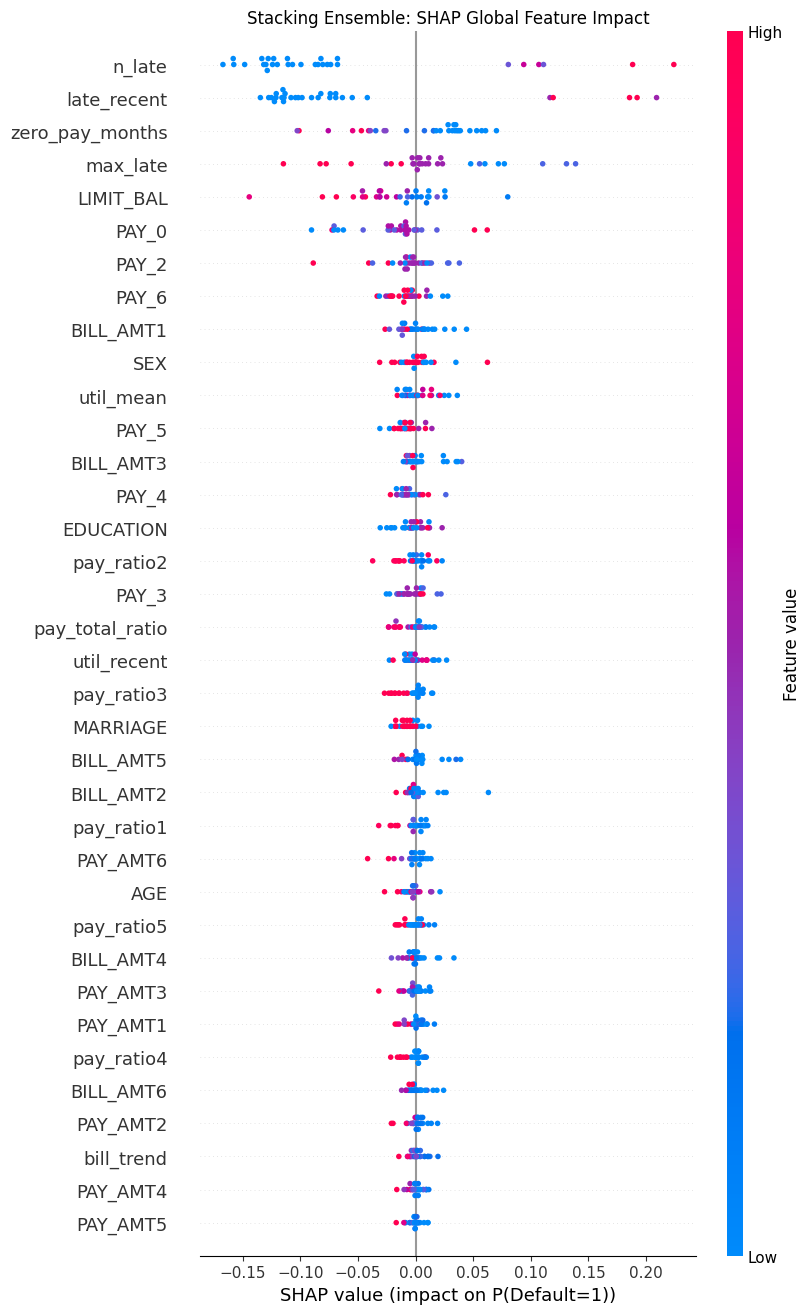

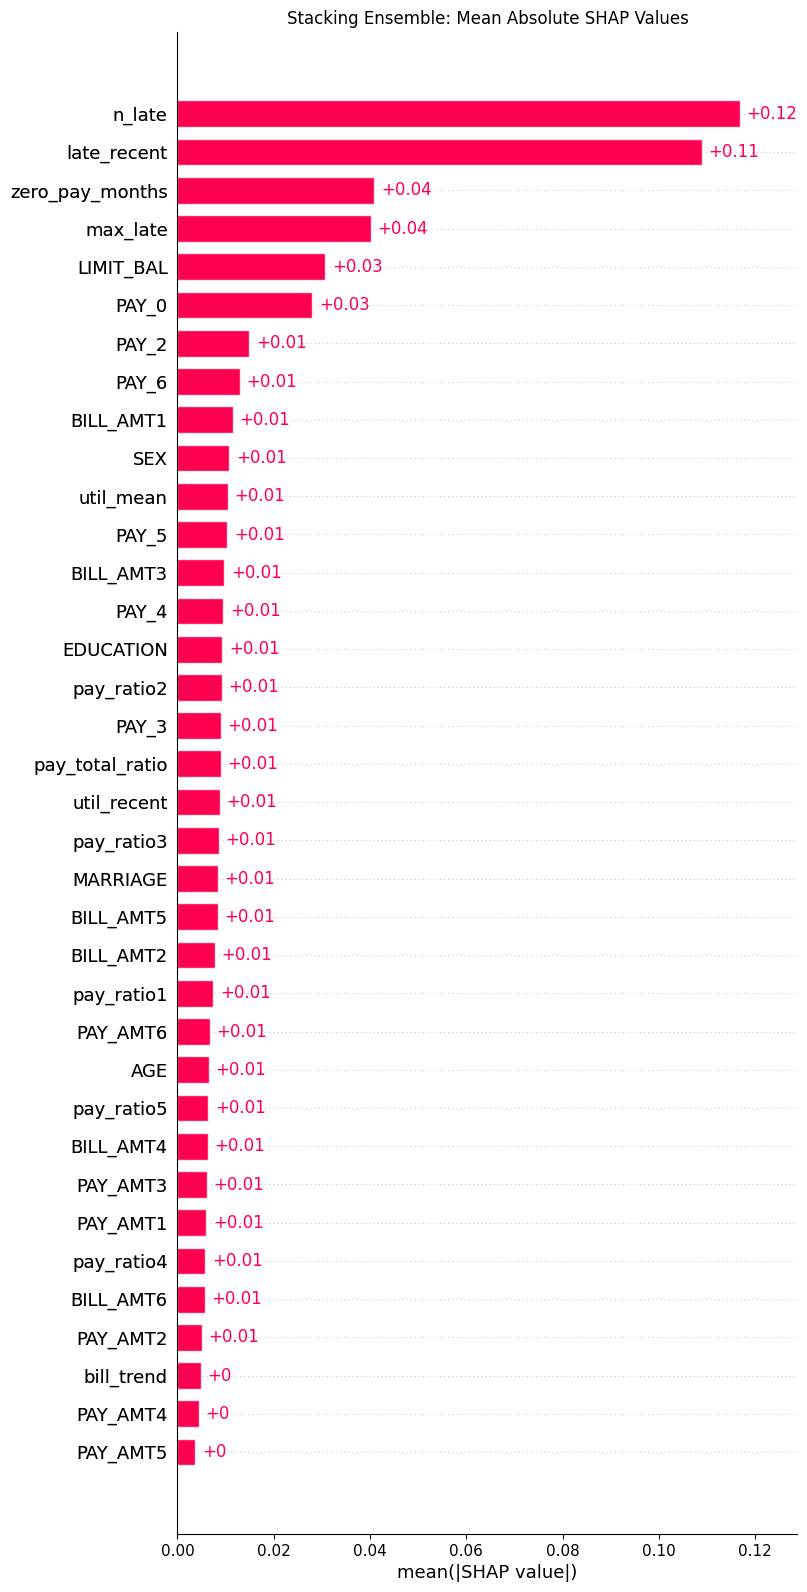

P(Default): 0.064444
SHAP base + contribution: 0.064444
Difference: 0.00000000


,Feature,Feature_value,SHAP_contribution,Absolute_SHAP
0,PAY_0,-2.000000,-0.090356,0.090356
1,late_recent,0.000000,-0.082266,0.082266
2,n_late,0.000000,-0.076690,0.076690
3,max_late,-2.000000,0.071824,0.071824
4,zero_pay_months,4.000000,-0.054672,0.054672
5,PAY_5,-2.000000,-0.031027,0.031027
6,LIMIT_BAL,280000.000000,-0.030342,0.030342
7,pay_ratio3,1.000000,-0.023326,0.023326
8,PAY_3,-2.000000,-0.022660,0.022660
9,EDUCATION,1.000000,-0.021493,0.021493


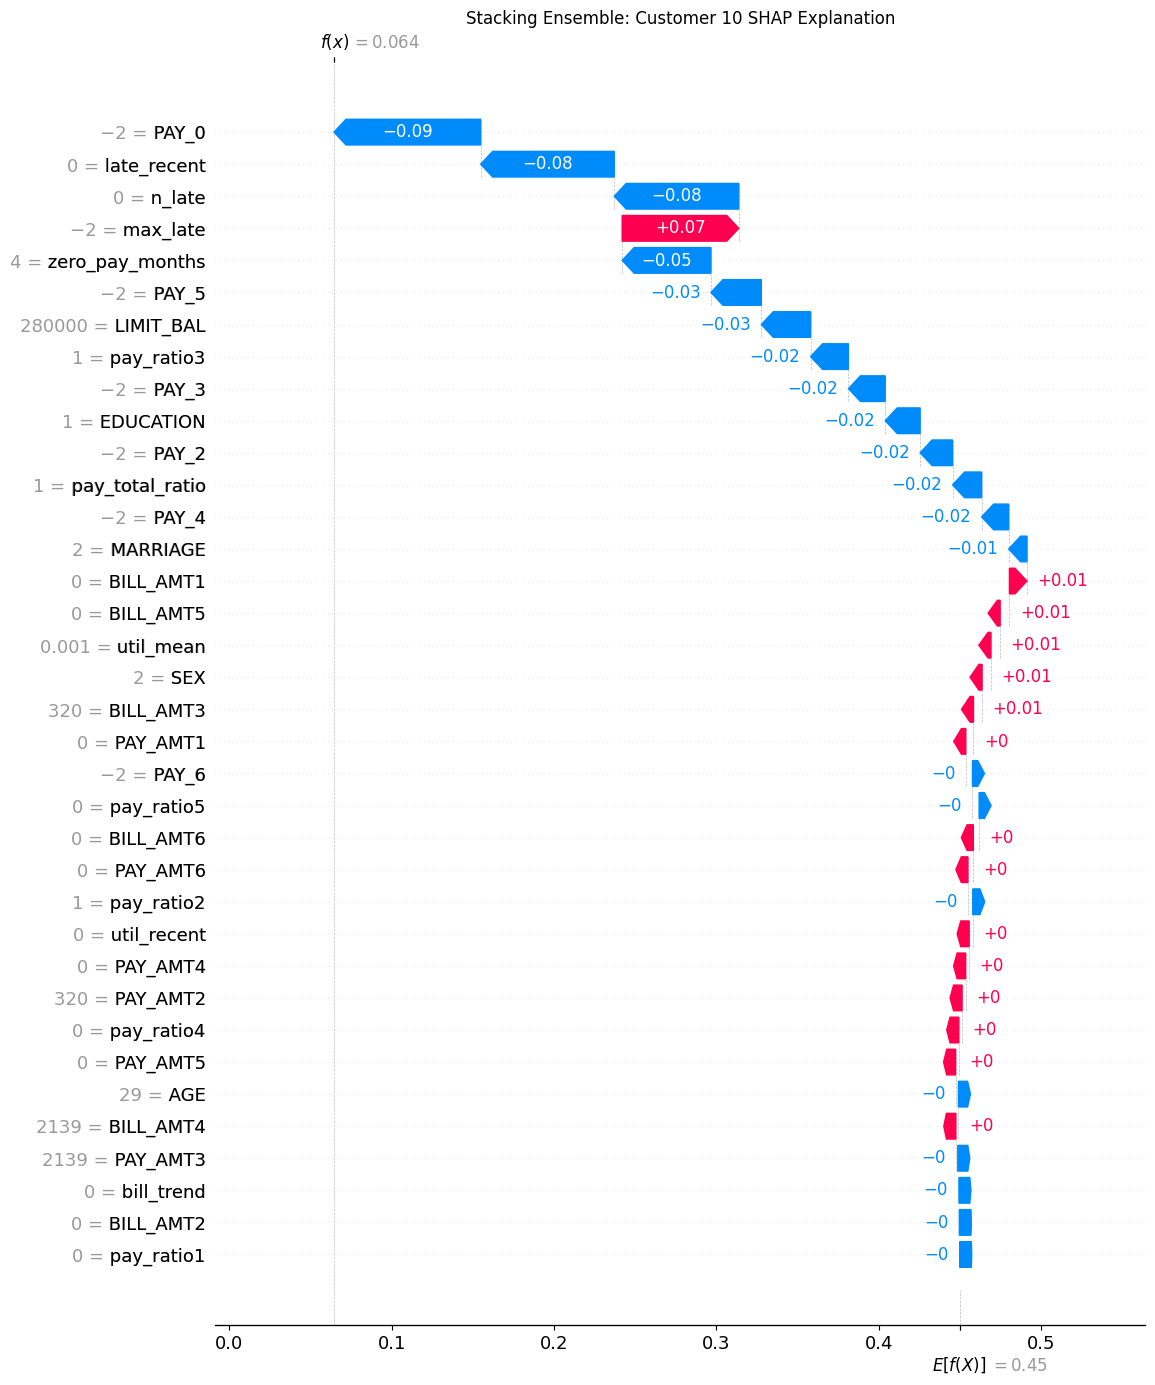

✓ XAI 3 completed successfully for Stacking Ensemble


In [ ]:
# ============================================================
# XAI 3 - SHAP Global + Local Explanation
# Stacking Ensemble Compatible
# Uses SHAP output from XAI 2
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap


# ============================================================
# 1. Check SHAP output
# ============================================================

if 'shap_explanation' not in globals():

    raise RuntimeError(
        "Run XAI 2 first. shap_explanation not found."
    )


print(
    "Using SHAP results from XAI 2"
)



# ============================================================
# 2. Global SHAP Beeswarm Plot
# ============================================================

if SHOW_PLOTS or SAVE_PLOTS:

    shap.plots.beeswarm(
        shap_explanation,
        max_display=N_FEATURES,
        show=False
    )


    plt.title(
        f'{model_name}: SHAP Global Feature Impact'
    )


    plt.xlabel(
        "SHAP value (impact on P(Default=1))"
    )


    finish_figure(
        "SHAP_beeswarm_stacking.png"
    )



# ============================================================
# 3. Global SHAP Bar Plot
# ============================================================

if SHOW_PLOTS or SAVE_PLOTS:

    shap.plots.bar(
        shap_explanation,
        max_display=N_FEATURES,
        show=False
    )


    plt.title(
        f'{model_name}: Mean Absolute SHAP Values'
    )


    finish_figure(
        "SHAP_global_bar_stacking.png"
    )



# ============================================================
# 4. Select Customer SHAP Explanation
# ============================================================

customer_frame = X_test_xai.iloc[
    [CUSTOMER_POSITION]
]


_local_matches = np.flatnonzero(
    shap_test_positions == CUSTOMER_POSITION
)


if len(_local_matches) == 0:

    raise RuntimeError(
        f"Customer {CUSTOMER_POSITION} not found. "
        "Run updated XAI 2 again."
    )


customer_shap_index = int(
    _local_matches[0]
)



customer_shap = shap_explanation[
    customer_shap_index
]



# ============================================================
# 5. Prediction and SHAP reconstruction
# ============================================================

customer_probability = float(
    predict_default(customer_frame)[0]
)



customer_shap_sum = float(
    customer_shap.base_values
    +
    customer_shap.values.sum()
)



print(
    f"P(Default): {customer_probability:.6f}"
)


print(
    f"SHAP base + contribution: {customer_shap_sum:.6f}"
)


print(
    f"Difference: {abs(customer_probability - customer_shap_sum):.8f}"
)



# ============================================================
# 6. Local SHAP Table
# ============================================================

shap_local = pd.DataFrame({

    "Feature":
        FEATURE_NAMES,


    "Feature_value":
        customer_frame.iloc[0].values,


    "SHAP_contribution":
        customer_shap.values,


    "Absolute_SHAP":
        np.abs(customer_shap.values)

})



shap_local = shap_local.sort_values(
    "Absolute_SHAP",
    ascending=False
).reset_index(drop=True)



show_all(
    shap_local
)



shap_local.to_csv(
    OUTPUT_DIR /
    f"SHAP_customer_{CUSTOMER_POSITION}_all_features.csv",
    index=False
)



# ============================================================
# 7. Waterfall Plot
# ============================================================

if SHOW_PLOTS or SAVE_PLOTS:


    shap.plots.waterfall(
        customer_shap,
        max_display=N_FEATURES,
        show=False
    )


    plt.gcf().set_size_inches(
        12,
        max(8, 0.4*N_FEATURES + 2)
    )


    plt.title(
        f'{model_name}: Customer {CUSTOMER_POSITION} SHAP Explanation'
    )


    finish_figure(
        f"SHAP_customer_{CUSTOMER_POSITION}_waterfall.png"
    )



print(
    "✓ XAI 3 completed successfully for Stacking Ensemble"
)

/tmp/ipykernel_1001/1470807575.py:148: UserWarning: Fractional categorical values detected. Keeping them continuous for model fidelity: SEX, EDUCATION, MARRIAGE, PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6, max_late
  warnings.warn(


,Rank,Feature,Feature_value,LIME_condition,LIME_local_weight,Absolute_LIME_weight
0,1,late_recent,0.000000,late_recent=0,-0.166014,0.166014
1,2,max_late,-2.000000,max_late <= 0.00,0.130352,0.130352
2,3,n_late,0.000000,n_late=0,-0.110321,0.110321
3,4,zero_pay_months,4.000000,zero_pay_months=4,-0.071257,0.071257
4,5,SEX,2.000000,1.00 < SEX <= 2.00,0.052087,0.052087
5,6,LIMIT_BAL,280000.000000,LIMIT_BAL > 219459.29,-0.039642,0.039642
6,7,pay_total_ratio,1.000000,pay_total_ratio > 0.50,-0.039247,0.039247
7,8,pay_ratio2,1.000000,pay_ratio2 > 0.27,-0.035839,0.035839
8,9,PAY_0,-2.000000,PAY_0 <= -0.19,-0.017404,0.017404
9,10,pay_ratio3,1.000000,pay_ratio3 > 0.21,-0.016341,0.016341


Actual model P(Default): 0.064444
LIME surrogate prediction: 0.528875
Absolute prediction gap: 0.464432
LIME local R²: 0.5901
LIME weights represent local surrogate coefficients, not global feature importance.


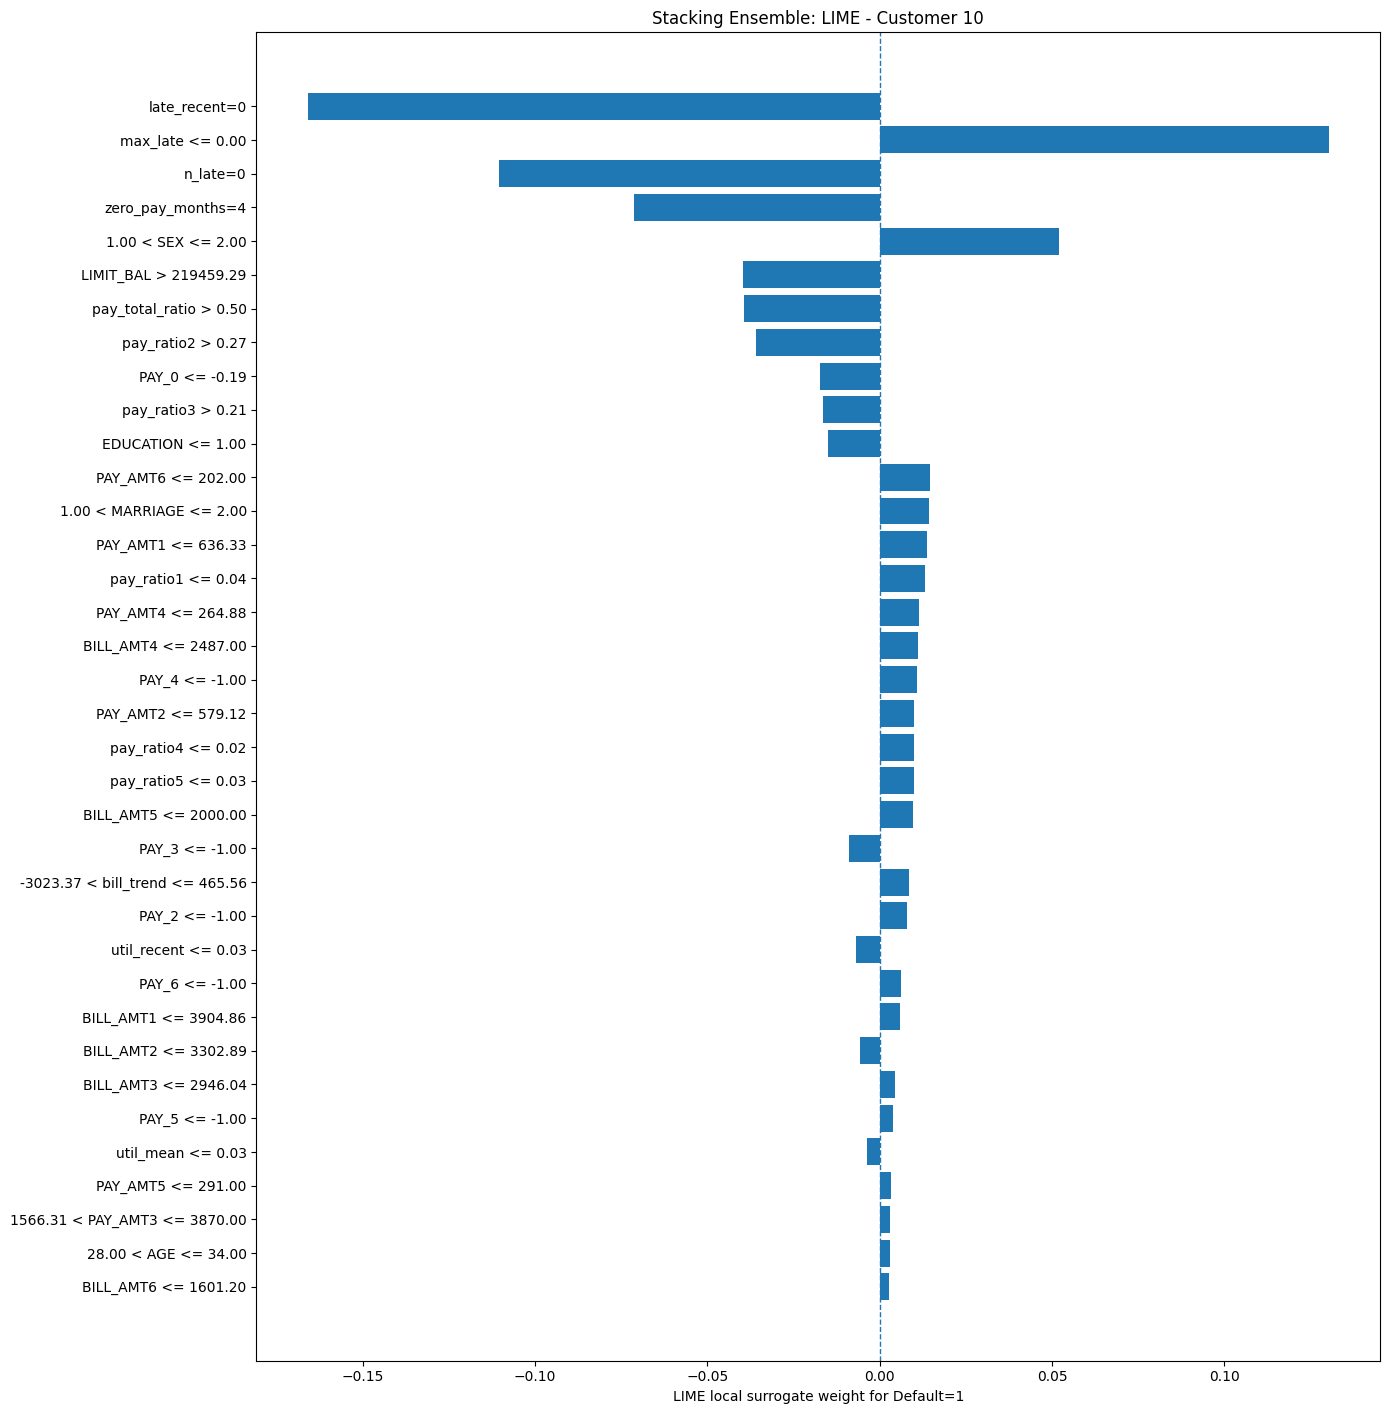

✓ XAI 4 LIME completed successfully for Stacking Ensemble


In [ ]:
# ============================================================
# XAI 4 - LIME Explanation
# Stacking Ensemble Compatible
# Same Customer, All Features
# ============================================================

try:

    from lime.lime_tabular import LimeTabularExplainer

except ImportError as exc:

    raise ImportError(
        "Install LIME first: %pip install -q lime==0.2.0.1"
    ) from exc



import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt



# ============================================================
# 1. Check required variables
# ============================================================

_required = [

    'customer_frame',
    'customer_probability',
    'predict_proba_named',
    'FEATURE_NAMES'

]


_missing = [

    x for x in _required

    if x not in globals()

]


if _missing:

    raise RuntimeError(
        "Run XAI 3 first. Missing: "
        + ", ".join(_missing)
    )



# ============================================================
# 2. Identify categorical features
# ============================================================


_categorical_candidates = [

    'SEX',
    'EDUCATION',
    'MARRIAGE',

    'PAY_0',
    'PAY_2',
    'PAY_3',
    'PAY_4',
    'PAY_5',
    'PAY_6',

    'n_late',
    'max_late',
    'late_recent',
    'zero_pay_months'

]



lime_categorical_indices = []

lime_fractional_category_columns = []



for feature in _categorical_candidates:


    if feature not in FEATURE_NAMES:

        continue



    values = X_train_xai[feature].to_numpy(
        dtype=float
    )


    customer_value = float(
        customer_frame.iloc[0][feature]
    )



    if (

        np.allclose(
            values,
            np.rint(values),
            atol=1e-8
        )

        and

        np.isclose(
            customer_value,
            round(customer_value),
            atol=1e-8
        )

    ):


        lime_categorical_indices.append(

            FEATURE_NAMES.index(feature)

        )


    else:


        lime_fractional_category_columns.append(
            feature
        )



if lime_fractional_category_columns:

    warnings.warn(

        "Fractional categorical values detected. "
        "Keeping them continuous for model fidelity: "
        +
        ", ".join(
            lime_fractional_category_columns
        ),

        stacklevel=1

    )



# ============================================================
# 3. Create LIME Explainer
# ============================================================


lime_explainer = LimeTabularExplainer(

    training_data=

        X_train_xai.to_numpy(
            dtype=float
        ),


    feature_names=

        FEATURE_NAMES,


    class_names=

        [
            "No Default",
            "Default"
        ],


    categorical_features=

        lime_categorical_indices,


    mode=

        "classification",


    discretize_continuous=

        True,


    feature_selection=

        "none",


    random_state=

        RANDOM_SEED

)



# ============================================================
# 4. Explain Customer
# ============================================================


lime_exp = lime_explainer.explain_instance(

    data_row=

        customer_frame.iloc[0].to_numpy(
            dtype=float
        ),


    predict_fn=

        predict_proba_named,


    labels=

        (
            DEFAULT_CLASS_INDEX,
        ),


    num_features=

        N_FEATURES,


    num_samples=

        LIME_NUM_SAMPLES

)



# ============================================================
# 5. Extract LIME Result
# ============================================================


_pairs = lime_exp.as_map()[

    DEFAULT_CLASS_INDEX

]



_conditions = dict(

    (

        int(pair[0]),

        name[0]

    )

    for pair, name in zip(

        _pairs,

        lime_exp.domain_mapper.map_exp_ids(
            _pairs
        )

    )

)



lime_result = pd.DataFrame(

    [

        {

            "Feature":

                FEATURE_NAMES[int(i)],


            "Feature_value":

                float(
                    customer_frame.iloc[0,int(i)]
                ),


            "LIME_condition":

                _conditions[int(i)],


            "LIME_local_weight":

                float(weight),


            "Absolute_LIME_weight":

                abs(float(weight))

        }


        for i, weight in _pairs

    ]

)



lime_result = lime_result.sort_values(

    "Absolute_LIME_weight",

    ascending=False

).reset_index(drop=True)



lime_result.insert(

    0,

    "Rank",

    np.arange(
        1,
        len(lime_result)+1
    )

)



# ============================================================
# 6. Display and Save
# ============================================================


show_all(
    lime_result
)



lime_result.to_csv(

    OUTPUT_DIR /

    f"LIME_customer_{CUSTOMER_POSITION}_all_features.csv",

    index=False

)



# ============================================================
# 7. LIME Performance
# ============================================================


lime_local_prediction = float(

    np.asarray(
        lime_exp.local_pred
    ).reshape(-1)[0]

)



lime_local_r2 = float(

    lime_exp.score

)



lime_prediction_gap = abs(

    customer_probability

    -

    lime_local_prediction

)



print(

    f"Actual model P(Default): {customer_probability:.6f}"

)


print(

    f"LIME surrogate prediction: {lime_local_prediction:.6f}"

)


print(

    f"Absolute prediction gap: {lime_prediction_gap:.6f}"

)


print(

    f"LIME local R²: {lime_local_r2:.4f}"

)



print(

    "LIME weights represent local surrogate coefficients, "
    "not global feature importance."

)



# ============================================================
# 8. LIME Plot
# ============================================================


if SHOW_PLOTS or SAVE_PLOTS:


    _plot = lime_result.iloc[::-1]


    plt.figure(

        figsize=(14, max(7,0.34*N_FEATURES+2))

    )


    plt.barh(

        _plot["LIME_condition"],

        _plot["LIME_local_weight"]

    )


    plt.axvline(

        0,

        linestyle="--",

        linewidth=1

    )


    plt.xlabel(

        "LIME local surrogate weight for Default=1"

    )


    plt.title(

        f"{model_name}: LIME - Customer {CUSTOMER_POSITION}"

    )


    plt.tight_layout()



    finish_figure(

        f"LIME_customer_{CUSTOMER_POSITION}_all_features.png"

    )



# ============================================================
# 9. Save HTML
# ============================================================


if SAVE_LIME_HTML:


    lime_exp.save_to_file(

        str(

            OUTPUT_DIR /

            f"LIME_customer_{CUSTOMER_POSITION}_all_features.html"

        ),


        labels=[

            DEFAULT_CLASS_INDEX

        ],

        show_all=True

    )



print(

    "✓ XAI 4 LIME completed successfully for Stacking Ensemble"

)

In [ ]:
# ============================================================
# XAI 5 - SHAP + LIME Comparison and Final Audit
# Stacking Ensemble Compatible Version
# ============================================================

import json
import shutil
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd



# ============================================================
# 1. Check Required Outputs
# ============================================================

_required = [

    "shap_local",
    "lime_result",
    "customer_probability",
    "customer_shap_sum",
    "model_name"

]


_missing = [

    x for x in _required

    if x not in globals()

]


if _missing:

    raise RuntimeError(

        "Run XAI 3 and XAI 4 first. Missing: "
        +
        ", ".join(_missing)

    )



# ============================================================
# 2. Clean LIME Feature Names
# ============================================================

lime_result_fixed = lime_result.copy()



def clean_lime_feature(x):

    x = str(x)

    for op in [

        " <= ",
        " >= ",
        " < ",
        " > ",
        "="

    ]:

        x = x.split(op)[0]


    return x.strip()



lime_result_fixed["Feature"] = (

    lime_result_fixed["Feature"]

    .apply(clean_lime_feature)

)



# ============================================================
# 3. SHAP + LIME Comparison
# ============================================================

comparison = shap_local[

    [

        "Feature",

        "Feature_value",

        "SHAP_contribution"

    ]

].merge(

    lime_result_fixed[

        [

            "Feature",

            "LIME_local_weight"

        ]

    ],

    on="Feature",

    how="left"

)



comparison = comparison.rename(

    columns={

        "LIME_local_weight":

        "LIME_weight"

    }

)



comparison["Absolute_SHAP"] = (

    np.abs(

        comparison["SHAP_contribution"]

    )

)



comparison["Absolute_LIME"] = (

    np.abs(

        comparison["LIME_weight"]

    )

)



show_all(
    comparison
)



comparison.to_csv(

    OUTPUT_DIR /

    f"SHAP_LIME_customer_{CUSTOMER_POSITION}_comparison.csv",

    index=False

)



print(

    "Missing LIME values:",

    comparison["LIME_weight"].isna().sum()

)



# ============================================================
# 4. SHAP Reconstruction Error
# ============================================================

shap_max_additivity_error = abs(

    float(customer_probability)

    -

    float(customer_shap_sum)

)



# ============================================================
# 5. Metadata
# ============================================================

_metadata = {


    "model":

        str(model_name),



    "model_type":

        str(type(model)),



    "n_features":

        int(N_FEATURES),



    "feature_names":

        FEATURE_NAMES,



    "explained_output":

        "Probability of Default = 1",



    "customer_test_position":

        int(CUSTOMER_POSITION),



    "customer_source_index":

        str(customer_frame.index[0]),



    "random_seed":

        int(RANDOM_SEED),



    "shap_method":

        str(shap_method)
        if "shap_method" in globals()
        else "PermutationExplainer",



    "shap_sample_count":

        int(len(X_shap))
        if "X_shap" in globals()
        else None,



    "background_count":

        int(len(X_background))
        if "X_background" in globals()
        else None,



    "max_shap_probability_reconstruction_error":

        float(shap_max_additivity_error),



    "customer_model_probability_default":

        float(customer_probability),



    "customer_shap_base_plus_sum":

        float(customer_shap_sum),



    # -------------------------
    # LIME
    # -------------------------


    "lime_num_samples":

        int(LIME_NUM_SAMPLES),



    "lime_local_r2":

        float(lime_local_r2),



    "lime_surrogate_prediction":

        float(lime_local_prediction),



    "lime_absolute_prediction_gap":

        float(lime_prediction_gap),



    "limitations":

    [

        "SHAP and LIME explain model behaviour, not causal relationships.",

        "LIME provides a local surrogate explanation.",

        "Global SHAP importance depends on evaluated samples.",

        "Interpretations describe the selected Stacking Ensemble model."

    ]

}



# ============================================================
# 6. Add Observed Label
# ============================================================

if "y_test" in globals():

    observed_label = (

        y_test.iloc[CUSTOMER_POSITION]

        if hasattr(y_test,"iloc")

        else np.asarray(y_test)[CUSTOMER_POSITION]

    )


    _metadata["customer_observed_label"] = int(
        observed_label
    )



# ============================================================
# 7. Save Metadata
# ============================================================

(OUTPUT_DIR / "XAI_run_metadata.json").write_text(

    json.dumps(

        _metadata,

        indent=2,

        default=str

    ),

    encoding="utf-8"

)



# ============================================================
# 8. Create Final ZIP
# ============================================================

archive_path = shutil.make_archive(

    str(

        OUTPUT_ROOT /

        "Stacking_Ensemble_XAI_results"

    ),

    "zip",

    root_dir=OUTPUT_DIR

)



print(

    "✓ Completed: SHAP + LIME analysis for all features."

)


print(

    f"Model used: {model_name}"

)


print(

    f"Output folder: {OUTPUT_DIR.resolve()}"

)


print(

    f"ZIP archive: {Path(archive_path).resolve()}"

)

,Feature,Feature_value,SHAP_contribution,LIME_weight,Absolute_SHAP,Absolute_LIME
0,PAY_0,-2.000000,-0.090356,-0.017404,0.090356,0.017404
1,late_recent,0.000000,-0.082266,-0.166014,0.082266,0.166014
2,n_late,0.000000,-0.076690,-0.110321,0.076690,0.110321
3,max_late,-2.000000,0.071824,0.130352,0.071824,0.130352
4,zero_pay_months,4.000000,-0.054672,-0.071257,0.054672,0.071257
5,PAY_5,-2.000000,-0.031027,0.003843,0.031027,0.003843
6,LIMIT_BAL,280000.000000,-0.030342,-0.039642,0.030342,0.039642
7,pay_ratio3,1.000000,-0.023326,-0.016341,0.023326,0.016341
8,PAY_3,-2.000000,-0.022660,-0.008856,0.022660,0.008856
9,EDUCATION,1.000000,-0.021493,-0.014886,0.021493,0.014886


Missing LIME values: 0
✓ Completed: SHAP + LIME analysis for all features.
Model used: Stacking Ensemble
Output folder: /content/XAI_all_features/Stacking_Ensemble
ZIP archive: /content/XAI_all_features/Stacking_Ensemble_XAI_results.zip


In [ ]:
print(model_name)
print(type(model))

Stacking Ensemble
<class 'sklearn.ensemble._stacking.StackingClassifier'>
